📁 Project root detected: /Users/arushisingh/pds-2025-opioids-straight-as-7
📄 Loading data from: /Users/arushisingh/pds-2025-opioids-straight-as-7/00_data/processed/master_county_year_panel.csv


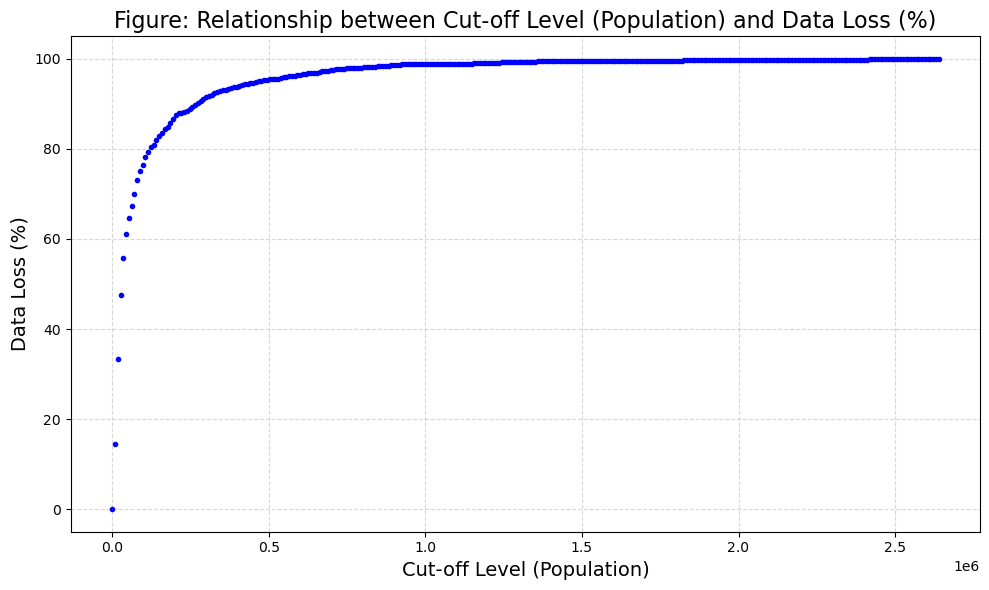

In [ ]:
# ------------------------------------------------------------
# Cutoff-Level (Population) vs Data Loss Plot
# ------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Resolve project root automatically
# ------------------------------------------------------------

# Walk up until we find the project folder containing 00_data
current = Path().resolve()
project_root = None

for parent in [current, *current.parents]:
    if (parent / "00_data" / "processed").exists():
        project_root = parent
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate '00_data/processed' folder. Check directory structure."
    )

print(f"📁 Project root detected: {project_root}")

# ------------------------------------------------------------
# 2. Load the master dataset
# ------------------------------------------------------------
data_path = project_root / "00_data" / "processed" / "master_county_year_panel.csv"

print(f"📄 Loading data from: {data_path}")

df = pd.read_csv(data_path)

# Ensure population column exists
pop_col = "population"
if pop_col not in df.columns:
    raise ValueError(
        f"Column '{pop_col}' not found in dataset. Available columns: {df.columns}"
    )

# ------------------------------------------------------------
# 3. Compute cutoff levels & data loss percentages
# ------------------------------------------------------------
pop_values = df[pop_col].dropna()

cutoffs = np.linspace(0, pop_values.max(), 300)
loss_percentages = [(pop_values < c).mean() * 100 for c in cutoffs]

# ------------------------------------------------------------
# 4. Plot
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.plot(cutoffs, loss_percentages, "o", markersize=3, color="blue")

plt.title(
    "Figure: Relationship between Cut-off Level (Population) and Data Loss (%)",
    fontsize=16,
)
plt.xlabel("Cut-off Level (Population)", fontsize=14)
plt.ylabel("Data Loss (%)", fontsize=14)

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

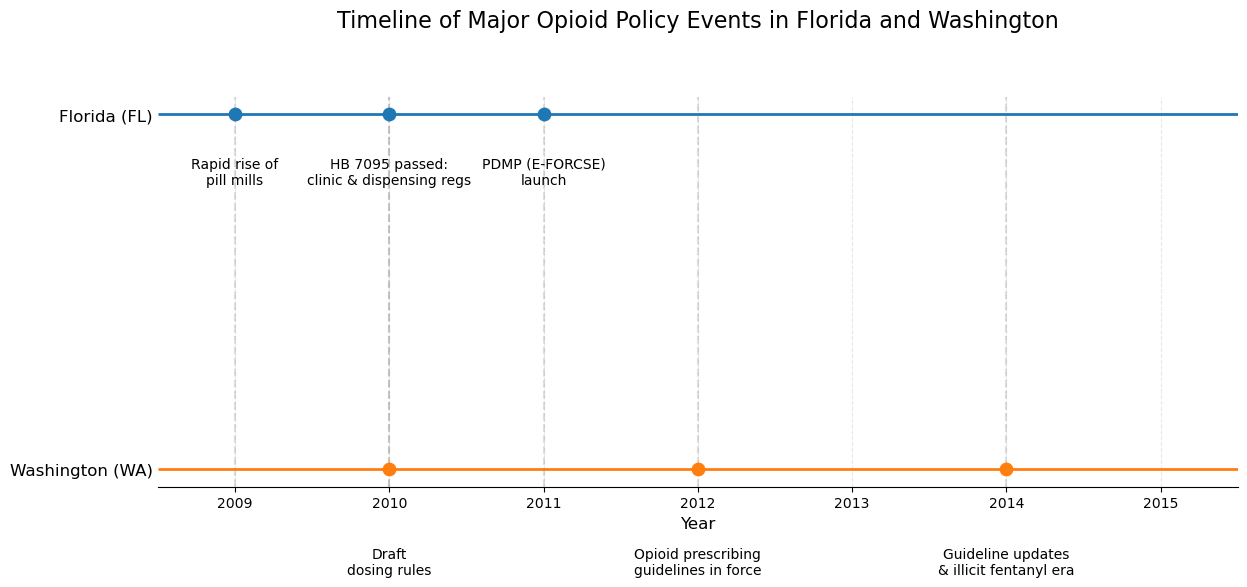

In [ ]:
import matplotlib.pyplot as plt

# -------------------------------------------------
# Policy timeline events for FL and WA
# -------------------------------------------------
fl_events = [
    (2009, "Rapid rise of\npill mills"),
    (2010, "HB 7095 passed:\nclinic & dispensing regs"),
    (2011, "PDMP (E-FORCSE)\nlaunch"),
]

wa_events = [
    (2010, "Draft\ndosing rules"),
    (2012, "Opioid prescribing\nguidelines in force"),
    (2014, "Guideline updates\n& illicit fentanyl era"),
]

fig, ax = plt.subplots(figsize=(12, 6))

# -------------------------------------------------
# Move entire axes DOWN to protect the title
# -------------------------------------------------
ax.set_position([0.08, 0.25, 0.9, 0.65])
# left, bottom, width, height

# Horizontal lines
ax.hlines(1, 2008.5, 2015.5, lw=2, color="tab:blue")
ax.hlines(0, 2008.5, 2015.5, lw=2, color="tab:orange")

# FL events
for year, label in fl_events:
    ax.scatter(year, 1, s=80, color="tab:blue", zorder=3)
    ax.text(
        year,
        0.88,  # LOWERED from 1.16 → 0.88
        label,
        ha="center",
        va="top",
        fontsize=10,
    )

# WA events
for year, label in wa_events:
    ax.scatter(year, 0, s=80, color="tab:orange", zorder=3)
    ax.text(
        year,
        -0.22,  # LOWERED further from line
        label,
        ha="center",
        va="top",
        fontsize=10,
    )

# Vertical dotted lines
all_years = [y for y, _ in fl_events + wa_events]
for year in all_years:
    ax.axvline(year, color="grey", linestyle="--", alpha=0.25)

# Axis formatting
ax.set_xlim(2008.5, 2015.5)
ax.set_xticks(range(2009, 2016))
ax.set_xlabel("Year", fontsize=12)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Washington (WA)", "Florida (FL)"], fontsize=12)

ax.set_title(
    "Timeline of Major Opioid Policy Events in Florida and Washington",
    fontsize=16,
    pad=50,  # EXTRA padding above title
)

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.tick_params(axis="y", length=0)

plt.savefig("policy_timeline.png", dpi=300, bbox_inches="tight")
plt.show()